# Credit Card Fraud Detection with Graph Neural Networks

This project uses a **Graph Neural Network (GNN)** built with **PyTorch Geometric** to detect fraudulent credit-card transactions. It compares the GNN with a normal neural network (MLP) that sees each transaction on its own.

**Data:** IBM synthetic credit-card transactions (Kaggle), one customer (User 0): 19,963 transactions, 27 of them fraudulent.

**Idea:** a fraudulent transaction often only looks suspicious *in context*, for example a sudden online purchase on a card that is usually swiped. A GNN lets each transaction look at its neighbours: the card's other recent transactions and the merchant's other recent transactions.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e6e6',
                     'axes.axisbelow': True})
BLUE, ORANGE, GREEN = '#2a78d6', '#eb6834', '#1baf7a'

## 2. Load and clean the data

In [2]:
df = pd.read_csv('User0_credit_card_transactions.csv')
print(df.shape)
df.head()

(19963, 15)


,User,Card,Year,Month,Day,Time,Amount,Use Chip,Merchant Name,Merchant City,Merchant State,Zip,MCC,Errors?,Is Fraud?
0,0,0,2002,9,1,06:21,$134.09,Swipe Transaction,3527213246127876953,La Verne,CA,91750.0,5300,NaN,No
1,0,0,2002,9,1,06:42,$38.48,Swipe Transaction,-727612092139916043,Monterey Park,CA,91754.0,5411,NaN,No
2,0,0,2002,9,2,06:22,$120.34,Swipe Transaction,-727612092139916043,Monterey Park,CA,91754.0,5411,NaN,No
3,0,0,2002,9,2,17:45,$128.95,Swipe Transaction,3414527459579106770,Monterey Park,CA,91754.0,5651,NaN,No
4,0,0,2002,9,3,06:23,$104.71,Swipe Transaction,5817218446178736267,La Verne,CA,91750.0,5912,NaN,No


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19963 entries, 0 to 19962
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   User            19963 non-null  int64  
 1   Card            19963 non-null  int64  
 2   Year            19963 non-null  int64  
 3   Month           19963 non-null  int64  
 4   Day             19963 non-null  int64  
 5   Time            19963 non-null  str    
 6   Amount          19963 non-null  str    
 7   Use Chip        19963 non-null  str    
 8   Merchant Name   19963 non-null  int64  
 9   Merchant City   19963 non-null  str    
 10  Merchant State  18646 non-null  str    
 11  Zip             18316 non-null  float64
 12  MCC             19963 non-null  int64  
 13  Errors?         574 non-null    str    
 14  Is Fraud?       19963 non-null  str    
dtypes: float64(1), int64(7), str(7)
memory usage: 2.3 MB


In [4]:
df.isnull().sum()

User                  0
Card                  0
Year                  0
Month                 0
Day                   0
Time                  0
Amount                0
Use Chip              0
Merchant Name         0
Merchant City         0
Merchant State     1317
Zip                1647
MCC                   0
Errors?           19389
Is Fraud?             0
dtype: int64

* `Merchant State` and `Zip` are missing for online transactions, which have no physical location. They aren't used as features.
* `Errors?` is missing when there was no error, so it is filled with "None".

Other cleaning steps: remove the `$` from `Amount`, combine the date and time columns into one timestamp, convert the label to 1 / 0, and sort by time.

In [5]:
df['Amount'] = df['Amount'].str.replace('$', '', regex=False).astype(float)
df['Datetime'] = pd.to_datetime(df[['Year', 'Month', 'Day']]) + pd.to_timedelta(df['Time'] + ':00')
df['Errors?'] = df['Errors?'].fillna('None')
df['Is Fraud?'] = (df['Is Fraud?'] == 'Yes').astype(int)
df['Use Chip'] = df['Use Chip'].str.replace(' Transaction', '')
df = df.sort_values('Datetime').reset_index(drop=True)

df[['Card', 'Datetime', 'Amount', 'Use Chip', 'Merchant Name', 'Merchant City', 'MCC', 'Errors?', 'Is Fraud?']].head()

,Card,Datetime,Amount,Use Chip,Merchant Name,Merchant City,MCC,Errors?,Is Fraud?
0,0,2002-09-01 06:21:00,134.09,Swipe,3527213246127876953,La Verne,5300,None,0
1,0,2002-09-01 06:42:00,38.48,Swipe,-727612092139916043,Monterey Park,5411,None,0
2,0,2002-09-02 06:22:00,120.34,Swipe,-727612092139916043,Monterey Park,5411,None,0
3,0,2002-09-02 17:45:00,128.95,Swipe,3414527459579106770,Monterey Park,5651,None,0
4,0,2002-09-03 06:23:00,104.71,Swipe,5817218446178736267,La Verne,5912,None,0


## 3. Exploratory data analysis

### 3.1 Class imbalance

Legitimate: 19,936   Fraud: 27   (0.14% fraud)


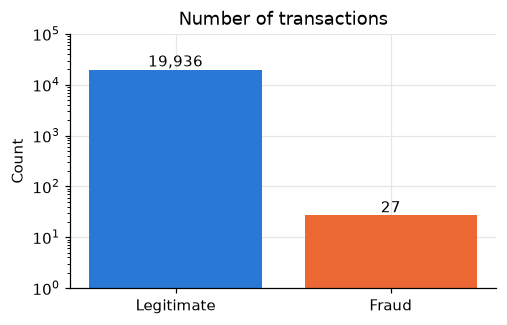

In [6]:
counts = df['Is Fraud?'].value_counts()
print(f"Legitimate: {counts[0]:,}   Fraud: {counts[1]}   ({counts[1] / len(df):.2%} fraud)")

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(['Legitimate', 'Fraud'], counts.values, color=[BLUE, ORANGE])
ax.set_yscale('log')
for i, v in enumerate(counts.values):
    ax.text(i, v * 1.15, f'{v:,}', ha='center')
ax.set(title='Number of transactions', ylabel='Count', ylim=(1, 1e5))
plt.show()

There are about 740 legitimate transactions for every fraudulent one. A model that always predicts "legitimate" would be 99.86% accurate, so accuracy is not a useful metric here.

### 3.2 Transactions over time

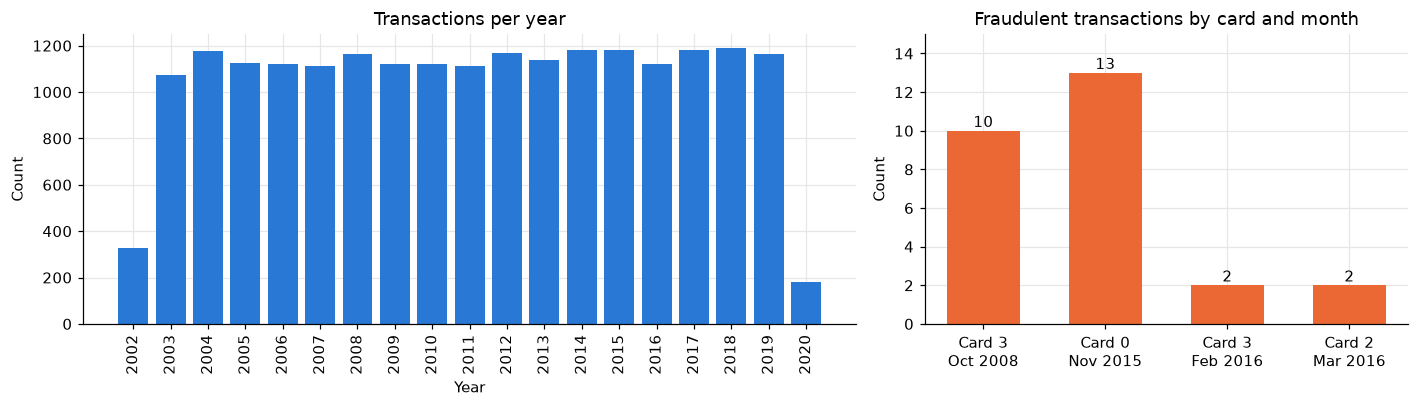

In [7]:
yearly = df.groupby('Year').size()

# Group the fraudulent transactions by card and month to see the bursts
fraud = df[df['Is Fraud?'] == 1]
bursts = fraud.groupby(['Card', fraud['Datetime'].dt.to_period('M')]).size().sort_index(level=1)
burst_labels = [f"Card {card}\n{month.strftime('%b %Y')}" for card, month in bursts.index]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={'width_ratios': [1.6, 1]})
axes[0].bar(yearly.index, yearly.values, color=BLUE)
axes[0].set(title='Transactions per year', xlabel='Year', ylabel='Count', xticks=yearly.index)
axes[0].tick_params(axis='x', rotation=90)

axes[1].bar(burst_labels, bursts.values, color=ORANGE, width=0.6)
for i, v in enumerate(bursts.values):
    axes[1].text(i, v + 0.2, str(v), ha='center')
axes[1].set(title=f'Fraudulent transactions by card and month', ylabel='Count', ylim=(0, 15))
plt.tight_layout()
plt.show()

Spending is steady at about 1,100 transactions a year; 2002 and 2020 are partial years. Fraud doesn't happen randomly: all 27 fraudulent transactions fall in just **four months**. Each time, a card is compromised and used several times over a few days, in October 2008, November 2015, February 2016 and March 2016.

### 3.3 How fraudulent transactions differ

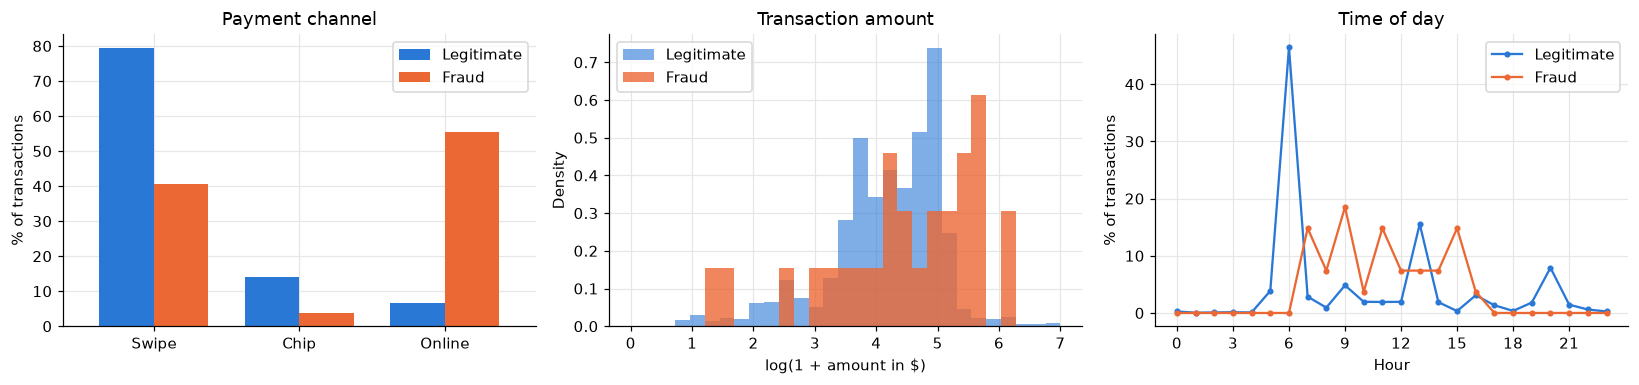

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))

channel = pd.crosstab(df['Use Chip'], df['Is Fraud?'], normalize='columns').loc[['Swipe', 'Chip', 'Online']] * 100
channel.columns = ['Legitimate', 'Fraud']
channel.plot.bar(ax=axes[0], color=[BLUE, ORANGE], rot=0, width=0.75)
axes[0].set(title='Payment channel', xlabel='', ylabel='% of transactions')

bins = np.linspace(0, 7, 30)
axes[1].hist(np.log1p(df.loc[df['Is Fraud?'] == 0, 'Amount'].abs()), bins=bins, density=True, alpha=0.6, color=BLUE, label='Legitimate')
axes[1].hist(np.log1p(df.loc[df['Is Fraud?'] == 1, 'Amount'].abs()), bins=bins, density=True, alpha=0.8, color=ORANGE, label='Fraud')
axes[1].set(title='Transaction amount', xlabel='log(1 + amount in $)', ylabel='Density')
axes[1].legend()

hours = np.arange(24)
for label, colour, name in [(0, BLUE, 'Legitimate'), (1, ORANGE, 'Fraud')]:
    share = df.loc[df['Is Fraud?'] == label, 'Datetime'].dt.hour.value_counts(normalize=True).reindex(hours, fill_value=0) * 100
    axes[2].plot(hours, share, marker='o', markersize=3, color=colour, label=name)
axes[2].set(title='Time of day', xlabel='Hour', ylabel='% of transactions', xticks=range(0, 24, 3))
axes[2].legend()
plt.tight_layout()
plt.show()

In [9]:
print('Average amount:  legitimate ${:.2f}   fraud ${:.2f}'.format(*df.groupby('Is Fraud?')['Amount'].mean()))
print('Fraud transactions with an error code:', (df.loc[df['Is Fraud?'] == 1, 'Errors?'] != 'None').sum())
print('\nMost common error codes overall:')
print(df.loc[df['Errors?'] != 'None', 'Errors?'].value_counts().head(5))

Average amount:  legitimate $81.28   fraud $96.94
Fraud transactions with an error code: 0

Most common error codes overall:
Errors?
Insufficient Balance    469
Technical Glitch         46
Bad PIN                  42
Bad Expiration            9
Bad Card Number           4
Name: count, dtype: int64


* Over half of fraudulent transactions are **online**, compared with 7% of legitimate ones.
* Fraud happens during the day, while this customer's normal spending peaks early in the morning.
* Amounts overlap a lot, and no fraud has an error code. These features alone won't find fraud.

### 3.4 Cards and merchants as a network
Linking each card to the merchants it buys from shows the structure the GNN will use.

5 cards, 552 merchants, 1077 card–merchant links (23 with fraud)


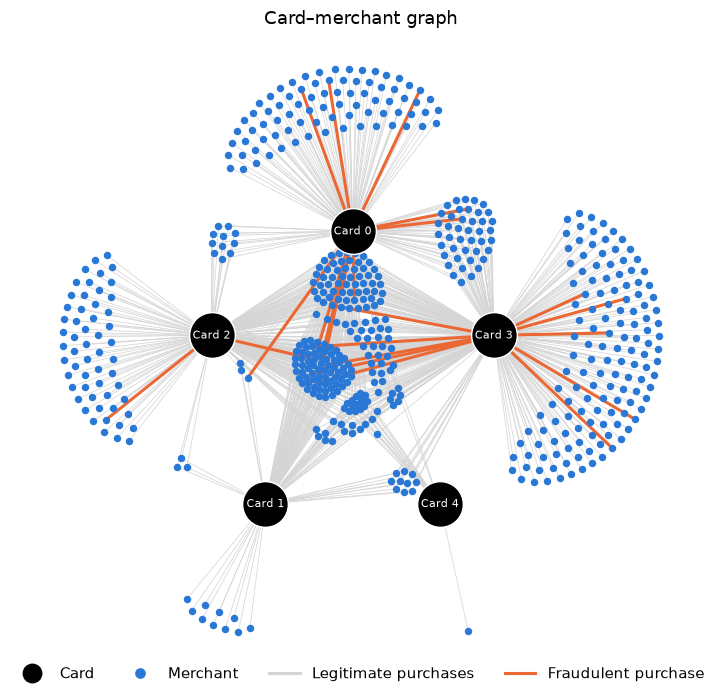

In [10]:
G = nx.Graph()
for (card, merchant), group in df.groupby(['Card', 'Merchant Name']):
    G.add_edge(f'Card {card}', merchant, fraud=group['Is Fraud?'].max() == 1)

cards = sorted(n for n in G if str(n).startswith('Card'))
merchants = [n for n in G if n not in cards]
fraud_edges = [e for e in G.edges if G.edges[e]['fraud']]
print(f'{len(cards)} cards, {len(merchants)} merchants, {G.number_of_edges()} card–merchant links ({len(fraud_edges)} with fraud)')

# Fix the cards in a circle so they don't overlap, and let the merchants arrange themselves around them
card_order = ['Card 0', 'Card 2', 'Card 1', 'Card 4', 'Card 3']
angles = np.linspace(0, 2 * np.pi, len(cards), endpoint=False) + np.pi / 2
fixed = {c: (np.cos(a), np.sin(a)) for c, a in zip(card_order, angles)}
pos = nx.spring_layout(G, pos=fixed, fixed=cards, k=0.15, iterations=200, seed=1)

fig, ax = plt.subplots(figsize=(8, 7.6))
nx.draw_networkx_edges(G, pos, ax=ax, edge_color='#d5d5d5', width=0.5)
nx.draw_networkx_edges(G, pos, ax=ax, edgelist=fraud_edges, edge_color=ORANGE, width=2)
nx.draw_networkx_nodes(G, pos, ax=ax, nodelist=merchants, node_size=15, node_color=BLUE)
nx.draw_networkx_nodes(G, pos, ax=ax, nodelist=cards, node_size=900, node_color='black', edgecolors='white')
nx.draw_networkx_labels(G, pos, ax=ax, labels={c: c for c in cards}, font_color='white', font_size=7)
ax.legend(handles=[plt.Line2D([], [], marker='o', ls='', color='black', markersize=12, label='Card'),
                   plt.Line2D([], [], marker='o', ls='', color=BLUE, markersize=6, label='Merchant'),
                   plt.Line2D([], [], color='#d5d5d5', lw=2, label='Legitimate purchases'),
                   plt.Line2D([], [], color=ORANGE, lw=2, label='Fraudulent purchase')],
          loc='upper center', bbox_to_anchor=(0.5, 0.03), ncol=4, frameon=False)
ax.set_title('Card–merchant graph', pad=0)
ax.margins(0.02)
ax.axis('off')
plt.show()

In [11]:
merchant_visits = df.groupby('Merchant Name').size()
busy = df['Merchant Name'].map(merchant_visits)
print(f"Median number of visits to the merchant: legitimate {busy[df['Is Fraud?'] == 0].median():.0f}, "
      f"fraud {busy[df['Is Fraud?'] == 1].median():.0f}")

Median number of visits to the merchant: legitimate 898, fraud 13


Each card has its own fan of merchants that only it uses (outside), while merchants shared by several cards sit in the middle. The 23 fraudulent links (orange) come from cards 0, 2 and 3 and go to both kinds of merchant, so the shape of the graph alone doesn't give fraud away. The GNN combines this structure with each transaction's features.

A typical legitimate purchase is at a merchant with hundreds of visits, while a fraudulent one is at a merchant with only a handful:

## 4. Node features
Each transaction becomes a node with a few simple features:

| Feature | Meaning |
|---|---|
| `log_amount` | size of the transaction |
| `hour` | time of day |
| `is_swipe`, `is_chip`, `is_online` | how the card was used |
| `has_error` | the transaction had an error (e.g. bad PIN) |
| `new_merchant` | first time this card has been used at this merchant |
| `hours_since_last` | time since the card's previous transaction |

In [12]:
features = pd.DataFrame({
    'log_amount': np.log1p(df['Amount'].abs()),
    'hour': df['Datetime'].dt.hour,
    'is_swipe': (df['Use Chip'] == 'Swipe').astype(int),
    'is_chip': (df['Use Chip'] == 'Chip').astype(int),
    'is_online': (df['Use Chip'] == 'Online').astype(int),
    'has_error': (df['Errors?'] != 'None').astype(int),
    'new_merchant': (df.groupby(['Card', 'Merchant Name']).cumcount() == 0).astype(int),
    'hours_since_last': np.log1p(df.groupby('Card')['Datetime'].diff().dt.total_seconds().fillna(0) / 3600),
})

x = StandardScaler().fit_transform(features)
y = df['Is Fraud?'].values
features.groupby(y).mean().T.rename(columns={0: 'legitimate (avg)', 1: 'fraud (avg)'}).round(2)

,legitimate (avg),fraud (avg)
log_amount,4.17,4.47
hour,9.89,11.00
is_swipe,0.79,0.41
is_chip,0.14,0.04
is_online,0.07,0.56
has_error,0.03,0.00
new_merchant,0.05,0.48
hours_since_last,2.58,1.26


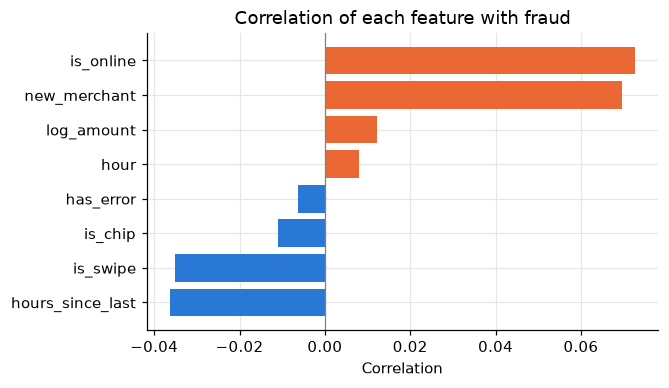

In [13]:
corr = features.assign(is_fraud=y).corr()['is_fraud'].drop('is_fraud').sort_values()
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.barh(corr.index, corr.values, color=[ORANGE if v > 0 else BLUE for v in corr.values])
ax.axvline(0, color='grey', lw=0.8)
ax.set(title='Correlation of each feature with fraud', xlabel='Correlation')
plt.show()

`new_merchant` and `is_online` are the features most linked to fraud. Correlations are small because fraud is so rare, but the differences in the averages table are large.